In [ ]:
import pandas as pd
import math

In [ ]:
data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain",
        "Rain", "Rain", "Overcast", "Sunny",
        "Sunny", "Rain", "Sunny", "Overcast",
        "Overcast", "Rain"
    ],

    "Temperature": [
        "Hot", "Hot", "Hot", "Mild",
        "Cool", "Cool", "Cool", "Mild",
        "Cool", "Mild", "Mild", "Mild",
        "Hot", "Mild"
    ],

    "Humidity": [
        "High", "High", "High", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "Normal", "Normal", "High",
        "Normal", "High"
    ],

    "Wind": [
        "Weak", "Strong", "Weak", "Weak",
        "Weak", "Strong", "Strong", "Weak",
        "Weak", "Weak", "Strong", "Strong",
        "Weak", "Strong"
    ],

    "Play": [
        "No", "No", "Yes", "Yes",
        "Yes", "No", "Yes", "No",
        "Yes", "Yes", "Yes", "Yes",
        "Yes", "No"
    ]
}

df = pd.DataFrame(data)

print(df)

     Outlook Temperature Humidity    Wind Play
0      Sunny         Hot     High    Weak   No
1      Sunny         Hot     High  Strong   No
2   Overcast         Hot     High    Weak  Yes
3       Rain        Mild     High    Weak  Yes
4       Rain        Cool   Normal    Weak  Yes
5       Rain        Cool   Normal  Strong   No
6   Overcast        Cool   Normal  Strong  Yes
7      Sunny        Mild     High    Weak   No
8      Sunny        Cool   Normal    Weak  Yes
9       Rain        Mild   Normal    Weak  Yes
10     Sunny        Mild   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
13      Rain        Mild     High  Strong   No


In [ ]:
def entropy(target):

  values = target.value_counts()
  total = len(target)

  entropy_values = 0

  for count in values:
    probability = count / total
    entropy_values -= probability * math.log2(probability)


  return entropy_values

In [ ]:
print("Entropy of dataset: ", entropy(df["Play"]))

Entropy of dataset:  0.9402859586706311


In [ ]:
def information_gain(data, attribute, target_name):

  total_entropy = entropy(data[target_name])
  values = data[attribute].unique()
  weighted_entropy = 0

  for value in values:
    subset = data[data[attribute] == value]
    probability = len(subset) / len(data)

    weighted_entropy += (
        probability *
        entropy(subset[target_name])

    )

  gain = total_entropy - weighted_entropy

  return gain

In [ ]:
attributes = [
    "Outlook", "Temperature", "Humidity", "Wind"
]

for attribute in attributes:

  gain = information_gain(
      df,
      attribute,
      "Play"
      )

  print(attribute, ":", gain)

Outlook : 0.24674981977443933
Temperature : 0.02922256565895487
Humidity : 0.15183550136234159
Wind : 0.04812703040826949


In [ ]:
def best_attribute(data, attributes, target_name):

  best_gain = -1
  best_attr = None

  for attribute in attributes:

    gain = information_gain(
        data,
        attribute,
        target_name
    )

    if gain > best_gain:
      best_gain = gain
      best_attr = attribute

  return best_attr

In [ ]:
attributes = [
    "Outlook", "Temperature", "Humidity", "Wind"
]

print(
    "Best attribute: ",
    best_attribute(df, attributes, "Play")
)

Best attribute:  Outlook


In [ ]:
def id3(data, attributes, target_name):

  if len(data[target_name].unique()) == 1:
    return data[target_name].iloc[0]

  if len(attributes) == 0:
    return data[target_name].mode()[0]

  best_attar = best_attribute(
      data,
      attributes,
      target_name
  )

  tree = {best_attar: {}}

  # Create a new list of attributes for the recursive call, excluding the best_attar
  new_attributes = [attr for attr in attributes if attr != best_attar]

  for value in data[best_attar].unique():

    subset = data[data[best_attar] == value
    ]

    tree[best_attar][value] = id3(
        subset,
        new_attributes,
        target_name
    )

  return tree

In [ ]:
attributes = [
    "Outlook", "Temperature", "Humidity", "Wind"
]

tree = id3(
    df,
    attributes,
    "Play"
)

print(
    "Decision Tree: ",
    tree
)

print(tree)

Decision Tree:  {'Outlook': {'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'Wind': {'Weak': 'Yes', 'Strong': 'No'}}}}
{'Outlook': {'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}, 'Overcast': 'Yes', 'Rain': {'Wind': {'Weak': 'Yes', 'Strong': 'No'}}}}


In [ ]:
def predict(tree, sample):

  if not isinstance(tree, dict):
    return tree

  attribute = list(tree.keys())[0]

  value = sample[attribute]

  subtree = tree[attribute][value]

  return predict(subtree, sample)

In [ ]:
new_sample = {
    "Outlook": "Sunny",
    "Temperature": "Cool",
    "Humidity": "High",
    "Wind": "Weak"
}

prediction = predict(tree, new_sample)

print("Prediction: ", prediction)


Prediction:  No


In [ ]:
predictions = []

for index, row in df.iterrows():
  sample = row.drop("Play").to_dict()

  prediction_result = predict(tree, sample)

  predictions.append(prediction_result)

df["Predicted"] = predictions

print(df)

     Outlook Temperature Humidity    Wind Play Predicted
0      Sunny         Hot     High    Weak   No        No
1      Sunny         Hot     High  Strong   No        No
2   Overcast         Hot     High    Weak  Yes       Yes
3       Rain        Mild     High    Weak  Yes       Yes
4       Rain        Cool   Normal    Weak  Yes       Yes
5       Rain        Cool   Normal  Strong   No        No
6   Overcast        Cool   Normal  Strong  Yes       Yes
7      Sunny        Mild     High    Weak   No        No
8      Sunny        Cool   Normal    Weak  Yes       Yes
9       Rain        Mild   Normal    Weak  Yes       Yes
10     Sunny        Mild   Normal  Strong  Yes       Yes
11  Overcast        Mild     High  Strong  Yes       Yes
12  Overcast         Hot   Normal    Weak  Yes       Yes
13      Rain        Mild     High  Strong   No        No


In [ ]:
correct = sum(
    df["Play"] == df["Predicted"]
)

accuracy = correct / len(df)

print("Accuracy: ", accuracy)

Accuracy:  1.0


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [ ]:
df_encoded = df.drop("Predicted", axis = 1).copy()

encoders = {}

for column in df_encoded.columns:
  encoder = LabelEncoder()

  df_encoded[column] = encoder.fit_transform(df_encoded[column])

  encoders[column] = encoder



In [ ]:
x = df_encoded.drop("Play", axis = 1)

y = df_encoded["Play"]

In [ ]:
model = DecisionTreeClassifier(
    criterion = "entropy",
    random_state = 42
)

model.fit(x, y)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [ ]:
y_pred = model.predict(x)

accuracy = accuracy_score(y, y_pred)

print("Accuracy", accuracy)

Accuracy 1.0


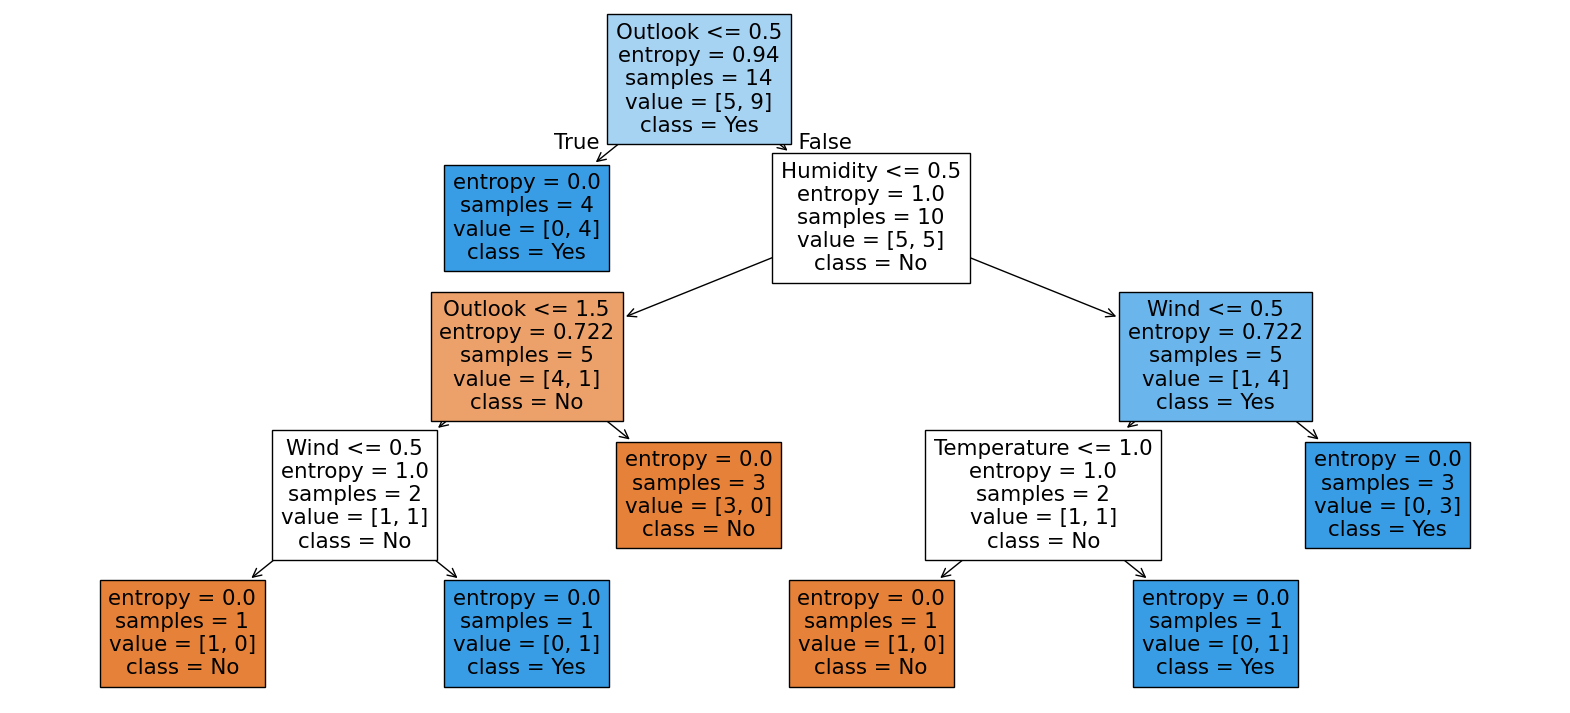

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize = (20, 9))

plot_tree(

         model,
         feature_names = x.columns,
         class_names = ["No", "Yes"],
         filled = True
)

plt.show()